Ce notebook fusionne :
- la **base communale complète** : INSEE + FINESS-SYGEN + RPPS ;
- l'**indicateur d'accessibilité aux médecins généralistes**.

La clé de fusion est `CODGEO` et la base complète reste la table principale.

Des analyses statistiques sont ensuite faites

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

In [2]:
URL_BASE_COMPLETE = (
    "https://minio.lab.sspcloud.fr/emma457/"
    "Projet_python/base_communes_finale.csv"
)

URL_INDICATEUR = (
    "https://minio.lab.sspcloud.fr/emma457/"
    "Projet_python/indicateur.parquet"
)

DOSSIER_SORTIE_LOCAL = Path("data/processed")
DOSSIER_SORTIE_LOCAL.mkdir(parents=True, exist_ok=True)

FICHIER_SORTIE_LOCAL = DOSSIER_SORTIE_LOCAL / "base_analyse_finale.parquet"

CHEMIN_S3_SORTIE = (
    "s3://catioui/projet_DS/processed/"
    "base_analyse_finale.parquet"
)

UPLOAD_MINIO = True

In [3]:
def systeme_fichiers_s3():
    import s3fs
    return s3fs.S3FileSystem(
        client_kwargs={
            "endpoint_url": "https://" + os.environ["AWS_S3_ENDPOINT"]
        }
    )

 Chargement des données

In [4]:
base_complete = pd.read_csv(
    URL_BASE_COMPLETE,
    dtype={"CODGEO": str},
    low_memory=False
)

indicateur = pd.read_parquet(URL_INDICATEUR)
indicateur["CODGEO"] = indicateur["CODGEO"].astype(str)

print("Base complète :", base_complete.shape)
print("Indicateur    :", indicateur.shape)

display(base_complete.head())
display(indicateur.head())

Base complète : (34858, 46)
Indicateur    : (34858, 11)


,CODGEO,LIBGEO,SEXE1_AGEPYR1000,SEXE1_AGEPYR1003,SEXE1_AGEPYR1006,SEXE1_AGEPYR1011,SEXE1_AGEPYR1018,SEXE1_AGEPYR1025,SEXE1_AGEPYR1040,SEXE1_AGEPYR1055,SEXE1_AGEPYR1065,SEXE1_AGEPYR1080,SEXE2_AGEPYR1000,SEXE2_AGEPYR1003,SEXE2_AGEPYR1006,SEXE2_AGEPYR1011,SEXE2_AGEPYR1018,SEXE2_AGEPYR1025,SEXE2_AGEPYR1040,SEXE2_AGEPYR1055,SEXE2_AGEPYR1065,SEXE2_AGEPYR1080,PMUN22,P1,P2,P3,DENS_AAV,LIBDENS_AAV,MED21,TP6021,RD21,LIT_MED,LIT_CHI,LIT_OBS,LIT_MCO,LIT_SMR,LIT_USLD,NB_SCAN,NB_IRM,NB_MAMM,nb_etablissements,DENS,LIBDENS,DENS7,LIBDENS7,nb_professionnels
0,01001,L'Abergement-Clémenciat,19.000000,15.000000,36.000000,42.000000,15.000000,77.000000,87.000000,66.000000,60.000000,20.000000,14.000000,13.000000,20.000000,39.000000,15.000000,74.000000,90.000000,65.000000,68.000000,24.000000,859.0,0.0,0.000000,100.000000,4.0,Rural non périurbain,25820,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,6,Rural à habitat dispersé,1
1,01002,L'Abergement-de-Varey,3.000000,6.000000,7.000000,22.000000,6.000000,20.000000,39.000000,12.000000,18.000000,10.000000,3.000000,6.000000,12.000000,12.000000,5.000000,21.000000,35.000000,14.000000,14.000000,8.000000,273.0,0.0,0.000000,100.000000,4.0,Rural non périurbain,24480,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,6,Rural à habitat dispersé,1
2,01004,Ambérieu-en-Bugey,291.774098,327.193219,525.370992,719.637562,733.735172,1581.246385,1344.792069,833.964093,888.674859,244.547759,323.969423,283.369968,467.591432,664.536778,736.655842,1518.093099,1408.495207,984.296766,1151.504227,524.551050,15554.0,0.0,96.933762,3.066238,2.0,Urbain intermédiaire,21660,17.0,3.1,31.0,27.0,15.0,73.0,NaN,NaN,NaN,NaN,NaN,3,2,Urbain intermédiaire,2,Centres urbains intermédiaires,521
3,01005,Ambérieux-en-Dombes,36.262404,37.108922,65.943276,80.082047,54.445778,193.448597,196.440979,137.738813,121.682540,36.336950,29.111892,33.799528,61.124887,81.584022,53.278755,195.596675,204.339272,131.092362,117.451751,50.130548,1917.0,0.0,0.000000,100.000000,3.0,Rural périurbain,24610,NaN,2.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,5,Bourgs ruraux,29
4,01006,Ambléon,2.000000,1.000000,2.000000,1.000000,4.000000,12.000000,11.000000,14.000000,11.000000,2.000000,1.000000,2.000000,2.000000,1.000000,2.000000,10.000000,7.000000,10.000000,15.000000,4.000000,114.0,0.0,0.000000,100.000000,4.0,Rural non périurbain,24210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,6,Rural à habitat dispersé,0


,CODGEO,LIBGEO,population,demande_standardisee,nb_medecins_generalistes,accessibilite_brute,accessibilite_ajustee_age,densite_mg,ratio_age_brute,decile_brute,decile_ajuste_age
0,01001,L'Abergement-Clémenciat,859.0,867.710799,0,60.835733,60.554914,0.000000,0.995384,3,4
1,01002,L'Abergement-de-Varey,273.0,270.430838,0,108.473487,110.057002,0.000000,1.014598,7,7
2,01004,Ambérieu-en-Bugey,15554.0,14951.854488,26,127.514910,130.705847,167.159573,1.025024,8,8
3,01005,Ambérieux-en-Dombes,1917.0,1861.977364,1,88.140910,89.489527,52.164841,1.015301,6,6
4,01006,Ambléon,114.0,124.706348,0,58.393214,56.284305,0.000000,0.963884,3,3


Contrôles avant fusion

In [5]:
base_complete["CODGEO"] = base_complete["CODGEO"].astype(str)
indicateur["CODGEO"] = indicateur["CODGEO"].astype(str)

print("Doublons base complète :", base_complete["CODGEO"].duplicated().sum())
print("Doublons indicateur :", indicateur["CODGEO"].duplicated().sum())

assert not base_complete["CODGEO"].duplicated().any()
assert not indicateur["CODGEO"].duplicated().any()

codes_base = set(base_complete["CODGEO"])
codes_indicateur = set(indicateur["CODGEO"])

print("Communes base complète :", len(codes_base))
print("Communes indicateur :", len(codes_indicateur))
print("Base sans indicateur :", len(codes_base - codes_indicateur))
print("Indicateur hors base :", len(codes_indicateur - codes_base))

Doublons base complète : 0
Doublons indicateur : 0
Communes base complète : 34858
Communes indicateur : 34858
Base sans indicateur : 0
Indicateur hors base : 0


Fusion

On ajoute seulement les variables propres à l'indicateur afin d'éviter de dupliquer les colonnes déjà présentes dans la base complète.

In [6]:
colonnes_indicateur = [
    "CODGEO",
    "population",
    "demande_standardisee",
    "nb_medecins_generalistes",
    "accessibilite_brute",
    "accessibilite_ajustee_age",
    "densite_mg",
    "ratio_age_brute",
    "decile_brute",
    "decile_ajuste_age",
]

colonnes_indicateur = [
    c for c in colonnes_indicateur
    if c in indicateur.columns
]

base_analyse = base_complete.merge(
    indicateur[colonnes_indicateur],
    on="CODGEO",
    how="left",
    validate="one_to_one"
)

print("Dimensions après fusion :", base_analyse.shape)
print("Communes :", base_analyse["CODGEO"].nunique())

assert len(base_analyse) == len(base_complete)
assert not base_analyse["CODGEO"].duplicated().any()

base_analyse.head()

Dimensions après fusion : (34858, 55)
Communes : 34858


,CODGEO,LIBGEO,SEXE1_AGEPYR1000,SEXE1_AGEPYR1003,SEXE1_AGEPYR1006,SEXE1_AGEPYR1011,SEXE1_AGEPYR1018,SEXE1_AGEPYR1025,SEXE1_AGEPYR1040,SEXE1_AGEPYR1055,SEXE1_AGEPYR1065,SEXE1_AGEPYR1080,SEXE2_AGEPYR1000,SEXE2_AGEPYR1003,SEXE2_AGEPYR1006,SEXE2_AGEPYR1011,SEXE2_AGEPYR1018,SEXE2_AGEPYR1025,SEXE2_AGEPYR1040,SEXE2_AGEPYR1055,SEXE2_AGEPYR1065,SEXE2_AGEPYR1080,PMUN22,P1,P2,P3,DENS_AAV,LIBDENS_AAV,MED21,TP6021,RD21,LIT_MED,LIT_CHI,LIT_OBS,LIT_MCO,LIT_SMR,LIT_USLD,NB_SCAN,NB_IRM,NB_MAMM,nb_etablissements,DENS,LIBDENS,DENS7,LIBDENS7,nb_professionnels,population,demande_standardisee,nb_medecins_generalistes,accessibilite_brute,accessibilite_ajustee_age,densite_mg,ratio_age_brute,decile_brute,decile_ajuste_age
0,01001,L'Abergement-Clémenciat,19.000000,15.000000,36.000000,42.000000,15.000000,77.000000,87.000000,66.000000,60.000000,20.000000,14.000000,13.000000,20.000000,39.000000,15.000000,74.000000,90.000000,65.000000,68.000000,24.000000,859.0,0.0,0.000000,100.000000,4.0,Rural non périurbain,25820,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,6,Rural à habitat dispersé,1,859.0,867.710799,0,60.835733,60.554914,0.000000,0.995384,3,4
1,01002,L'Abergement-de-Varey,3.000000,6.000000,7.000000,22.000000,6.000000,20.000000,39.000000,12.000000,18.000000,10.000000,3.000000,6.000000,12.000000,12.000000,5.000000,21.000000,35.000000,14.000000,14.000000,8.000000,273.0,0.0,0.000000,100.000000,4.0,Rural non périurbain,24480,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,6,Rural à habitat dispersé,1,273.0,270.430838,0,108.473487,110.057002,0.000000,1.014598,7,7
2,01004,Ambérieu-en-Bugey,291.774098,327.193219,525.370992,719.637562,733.735172,1581.246385,1344.792069,833.964093,888.674859,244.547759,323.969423,283.369968,467.591432,664.536778,736.655842,1518.093099,1408.495207,984.296766,1151.504227,524.551050,15554.0,0.0,96.933762,3.066238,2.0,Urbain intermédiaire,21660,17.0,3.1,31.0,27.0,15.0,73.0,NaN,NaN,NaN,NaN,NaN,3,2,Urbain intermédiaire,2,Centres urbains intermédiaires,521,15554.0,14951.854488,26,127.514910,130.705847,167.159573,1.025024,8,8
3,01005,Ambérieux-en-Dombes,36.262404,37.108922,65.943276,80.082047,54.445778,193.448597,196.440979,137.738813,121.682540,36.336950,29.111892,33.799528,61.124887,81.584022,53.278755,195.596675,204.339272,131.092362,117.451751,50.130548,1917.0,0.0,0.000000,100.000000,3.0,Rural périurbain,24610,NaN,2.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,5,Bourgs ruraux,29,1917.0,1861.977364,1,88.140910,89.489527,52.164841,1.015301,6,6
4,01006,Ambléon,2.000000,1.000000,2.000000,1.000000,4.000000,12.000000,11.000000,14.000000,11.000000,2.000000,1.000000,2.000000,2.000000,1.000000,2.000000,10.000000,7.000000,10.000000,15.000000,4.000000,114.0,0.0,0.000000,100.000000,4.0,Rural non périurbain,24210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Rural,6,Rural à habitat dispersé,0,114.0,124.706348,0,58.393214,56.284305,0.000000,0.963884,3,3


In [7]:
colonnes_acc = [
    c for c in [
        "accessibilite_brute",
        "accessibilite_ajustee_age"
    ]
    if c in base_analyse.columns
]

print("Valeurs manquantes sur les indicateurs :")
display(base_analyse[colonnes_acc].isna().sum())

Valeurs manquantes sur les indicateurs :


accessibilite_brute          0
accessibilite_ajustee_age    0
dtype: int64

Préparation des variables d'analyse

In [8]:
colonnes_numeriques = [
    "population",
    "demande_standardisee",
    "nb_medecins_generalistes",
    "accessibilite_brute",
    "accessibilite_ajustee_age",
    "densite_mg",
    "ratio_age_brute",
    "MED21",
    "TP6021",
    "RD21",
    "nb_etablissements",
    "nb_professionnels",
    "LIT_MCO",
    "LIT_SMR",
    "LIT_USLD",
    "NB_SCAN",
    "NB_IRM",
    "NB_MAMM",
]

for col in colonnes_numeriques:
    if col in base_analyse.columns:
        base_analyse[col] = pd.to_numeric(
            base_analyse[col],
            errors="coerce"
        )

cols_65_plus = [
    "SEXE1_AGEPYR1065",
    "SEXE1_AGEPYR1080",
    "SEXE2_AGEPYR1065",
    "SEXE2_AGEPYR1080",
]

if all(c in base_analyse.columns for c in cols_65_plus):
    for col in cols_65_plus:
        base_analyse[col] = pd.to_numeric(
            base_analyse[col],
            errors="coerce"
        )

    base_analyse["population_65_plus"] = (
        base_analyse[cols_65_plus].sum(axis=1)
    )

    base_analyse["part_65_plus_pct"] = np.where(
        base_analyse["population"] > 0,
        100 * base_analyse["population_65_plus"] / base_analyse["population"],
        np.nan
    )

print("Préparation terminée.")

Préparation terminée.


## Statistiques descriptives

In [9]:
variables_description = [
    c for c in [
        "accessibilite_brute",
        "accessibilite_ajustee_age",
        "densite_mg",
        "nb_medecins_generalistes",
        "population",
        "demande_standardisee",
    ]
    if c in base_analyse.columns
]

display(
    base_analyse[variables_description]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
    .T
)

,count,mean,std,min,10%,25%,50%,75%,90%,max
accessibilite_brute,34858.0,100.128734,72.172327,0.0,30.213002,55.239130,87.423233,129.497538,180.846742,2.551020e+03
accessibilite_ajustee_age,34858.0,95.563132,67.439869,0.0,28.706203,52.622991,83.861335,123.924531,172.818102,1.875782e+03
densite_mg,34848.0,55.463964,204.321118,0.0,0.000000,0.000000,0.000000,53.532596,182.581706,1.960784e+04
nb_medecins_generalistes,34858.0,3.204257,62.757709,0.0,0.000000,0.000000,0.000000,1.000000,5.000000,1.085800e+04
population,34858.0,1943.903064,14969.790638,0.0,101.000000,197.000000,459.000000,1169.000000,3215.200000,2.113705e+06
demande_standardisee,34858.0,1943.903064,14206.973663,0.0,107.980630,207.695676,469.801772,1201.242957,3358.232118,2.004215e+06


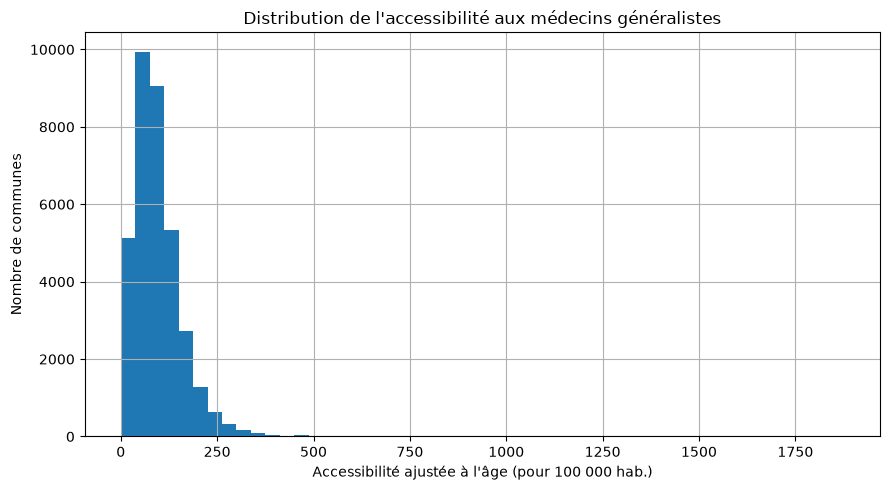

In [10]:
if "accessibilite_ajustee_age" in base_analyse.columns:
    plt.figure(figsize=(9, 5))
    base_analyse["accessibilite_ajustee_age"].dropna().hist(bins=50)
    plt.xlabel("Accessibilité ajustée à l'âge (pour 100 000 hab.)")
    plt.ylabel("Nombre de communes")
    plt.title("Distribution de l'accessibilité aux médecins généralistes")
    plt.tight_layout()
    plt.show()

## a. Inégalités selon la densité territoriale

In [11]:
if {"LIBDENS", "accessibilite_ajustee_age"}.issubset(base_analyse.columns):
    analyse_densite = (
        base_analyse
        .groupby("LIBDENS", dropna=False)
        .agg(
            nb_communes=("CODGEO", "count"),
            population=("population", "sum"),
            accessibilite_mediane=("accessibilite_ajustee_age", "median"),
            accessibilite_moyenne=("accessibilite_ajustee_age", "mean"),
            revenu_median=("MED21", "median"),
            taux_pauvrete_median=("TP6021", "median"),
        )
        .sort_values("accessibilite_mediane")
    )

    display(analyse_densite)

,nb_communes,population,accessibilite_mediane,accessibilite_moyenne,revenu_median,taux_pauvrete_median
LIBDENS,,,,,,
Rural,30591,21822546.0,77.942969,88.532277,22660.0,12.0
Urbain intermédiaire,3569,20756017.0,128.921369,138.965313,24460.0,12.0
Urbain dense,698,25182010.0,168.741933,181.778745,23830.0,14.0


## b. Liens avec les caractéristiques socio-économiques et sanitaires

In [12]:
variables_explicatives = [
    "MED21",
    "TP6021",
    "RD21",
    "part_65_plus_pct",
    "nb_etablissements",
    "nb_professionnels",
    "LIT_MCO",
    "LIT_SMR",
    "NB_SCAN",
    "NB_IRM",
]

variables_explicatives = [
    c for c in variables_explicatives
    if c in base_analyse.columns
]

if "accessibilite_ajustee_age" in base_analyse.columns:
    corr = (
        base_analyse[
            variables_explicatives + ["accessibilite_ajustee_age"]
        ]
        .corr(method="spearman")["accessibilite_ajustee_age"]
        .drop("accessibilite_ajustee_age")
        .sort_values()
        .to_frame("correlation_spearman")
    )

    display(corr)

,correlation_spearman
part_65_plus_pct,-0.057297
TP6021,0.056637
MED21,0.137953
LIT_SMR,0.216681
nb_etablissements,0.222461
RD21,0.231472
NB_SCAN,0.303214
NB_IRM,0.336448
nb_professionnels,0.348930
LIT_MCO,0.440334


## c. Communes les moins et les mieux accessibles

In [13]:
colonnes_affichage = [
    c for c in [
        "CODGEO",
        "LIBGEO",
        "LIBDENS",
        "population",
        "nb_medecins_generalistes",
        "accessibilite_ajustee_age",
        "MED21",
        "TP6021",
        "part_65_plus_pct",
        "nb_etablissements",
        "nb_professionnels",
    ]
    if c in base_analyse.columns
]

if "accessibilite_ajustee_age" in base_analyse.columns:
    peuplees = base_analyse.copy()

    if "population" in peuplees.columns:
        peuplees = peuplees[peuplees["population"].fillna(0) > 0]

    print("20 communes les moins accessibles")
    display(
        peuplees
        .nsmallest(20, "accessibilite_ajustee_age")[colonnes_affichage]
    )

    print("20 communes les plus accessibles")
    display(
        peuplees
        .nlargest(20, "accessibilite_ajustee_age")[colonnes_affichage]
    )

20 communes les moins accessibles


,CODGEO,LIBGEO,LIBDENS,population,nb_medecins_generalistes,accessibilite_ajustee_age,MED21,TP6021,part_65_plus_pct,nb_etablissements,nb_professionnels
58,01066,La Burbanche,Rural,97.0,0,0.0,NaN,NaN,16.853933,0,0
71,01080,Champdor-Corcelles,Rural,655.0,0,0.0,23720.0,NaN,22.061216,0,0
117,01135,Crozet,Urbain intermédiaire,2354.0,0,0.0,44040.0,10.0,11.246576,0,6
133,01153,Échenevex,Urbain intermédiaire,2227.0,0,0.0,49930.0,NaN,11.393224,0,0
179,01210,Lélex,Rural,236.0,0,0.0,24020.0,NaN,16.581925,0,0
184,01215,Surjoux-Lhopital,Rural,140.0,0,0.0,23850.0,NaN,18.840580,0,0
443,02055,Beaumé,Rural,84.0,0,0.0,NaN,NaN,33.750000,0,0
1254,03067,Châtelperron,Rural,132.0,0,0.0,20840.0,NaN,23.134328,0,0
1514,04016,Authon,Rural,59.0,0,0.0,NaN,NaN,22.807018,0,0
1518,04020,Barles,Rural,124.0,0,0.0,NaN,NaN,19.819820,0,1


20 communes les plus accessibles


,CODGEO,LIBGEO,LIBDENS,population,nb_medecins_generalistes,accessibilite_ajustee_age,MED21,TP6021,part_65_plus_pct,nb_etablissements,nb_professionnels
5540,17004,Île-d'Aix,Rural,196.0,5,1875.781806,22100.0,NaN,48.033914,0,9
7624,23020,Bellegarde-en-Marche,Rural,357.0,70,1131.414705,21510.0,NaN,43.697479,0,86
7774,23179,Saint-Alpinien,Rural,290.0,0,1129.443263,20790.0,NaN,25.317198,0,0
7662,23059,La Chaussade,Rural,97.0,0,1125.017001,NaN,NaN,26.000000,0,0
17438,48147,Saint-Étienne-du-Valdonnez,Rural,641.0,7,1108.648804,21220.0,NaN,19.151392,0,18
2277,07262,Saint-Laurent-les-Bains-Laval-d'Aurelle,Rural,184.0,3,1077.910810,17430.0,NaN,35.326087,0,5
7835,23241,Saint-Silvain-Bellegarde,Rural,198.0,0,1074.870011,18960.0,NaN,34.920635,0,0
7631,23028,Bosroger,Rural,117.0,0,1072.898569,18260.0,NaN,17.094017,0,0
7651,23048,Champagnat,Rural,480.0,0,1052.216258,19680.0,NaN,29.292610,0,0
7714,23113,Lupersat,Rural,291.0,0,1047.610924,18160.0,NaN,32.309896,0,0


## Sauvegarde de la base d'analyse

In [14]:
base_analyse.to_parquet(
    FICHIER_SORTIE_LOCAL,
    index=False
)

print("Fichier local :", FICHIER_SORTIE_LOCAL)

if UPLOAD_MINIO:
    fs = systeme_fichiers_s3()
    fs.put(
        str(FICHIER_SORTIE_LOCAL),
        CHEMIN_S3_SORTIE
    )
    print("Upload terminé : s3://" + CHEMIN_S3_SORTIE)
else:
    print("Upload MinIO désactivé.")

Fichier local : data/processed/base_analyse_finale.parquet
Upload terminé : s3://s3://catioui/projet_DS/processed/base_analyse_finale.parquet
